# **NAMA  : NADIA FAHRANI**
# **NIM   : H061251043**
# **KELAS : B**

# 5 Prompt Geofisika dengan Struktur R–T–C–I–K–O–Q–V

## Struktur Prompt

| Kode | Komponen | Penjelasan |
|:---:|---|---|
| **R** | **Role** | Peran AI yang harus dijalankan |
| **T** | **Task** | Tugas yang harus dikerjakan |
| **C** | **Context** | Latar belakang atau konteks masalah |
| **I** | **Input** | Data yang diberikan |
| **K** | **Constraints** | Batasan atau ketentuan |
| **O** | **Output** | Hasil yang diharapkan |
| **Q** | **Quality Criteria** | Kriteria kualitas hasil |
| **V** | **Verification** | Verifikasi atau pengecekan hasil |

---

# Prompt 1 — Interpretasi Data Geolistrik Resistivitas

### R — Role

Kamu berperan sebagai **ahli geofisika yang fokus pada metode geolistrik resistivitas**.

### T — Task

Interpretasikan data resistivitas untuk mengidentifikasi kemungkinan lapisan bawah permukaan dan material penyusunnya.

### C — Context

Survei dilakukan untuk mengetahui kondisi bawah permukaan.

### I — Input

Data yang saya berikan berupa nilai resistivitas semu, kedalaman, dan posisi titik pengukuran.

### K — Constraints

- Gunakan hanya data yang tersedia.
- Jangan menentukan jenis batuan secara mutlak hanya berdasarkan satu nilai resistivitas.
- Gunakan kata "kemungkinan" jika hasil interpretasi belum pasti dan jelaskan alasan setiap interpretasi.

### O — Output

Berikan tabel yang berisi kedalaman, nilai resistivitas, kemungkinan material, dan alasan interpretasinya. Setelah itu jelaskan kondisi bawah permukaan secara sederhana.

### Q — Quality Criteria

Pastikan setiap interpretasi konsisten dengan nilai resistivitas dan kedalaman yang diberikan.

### V — Verification

Periksa kembali logika urutan kedalaman dan kesesuaian rentang nilai resistivitas dengan material yang ditebak.

---

TABEL INTERPRETASI RESISTIVITAS
 Posisi (m)  Kedalaman (m)  Resistivitas (Ohm m)                               Kemungkinan Material                                                        Alasan Interpretasi
          0              1                    25      Kemungkinan lempung, lanau, atau tanah lembap            Material konduktif dan kadar air dapat menurunkan resistivitas.
          5              2                    12      Kemungkinan lempung, lanau, atau tanah lembap            Material konduktif dan kadar air dapat menurunkan resistivitas.
         10              3                    45 Kemungkinan tanah pelapukan atau material campuran Rentang ini dapat dijumpai pada beragam material dengan kadar air berbeda.
         15              2                   150        Kemungkinan pasir/kerikil atau batuan lapuk   Resistivitas relatif tinggi dapat menunjukkan material kurang jenuh air.
         20              1                   600     Kemungkinan batuan kompak atau material 

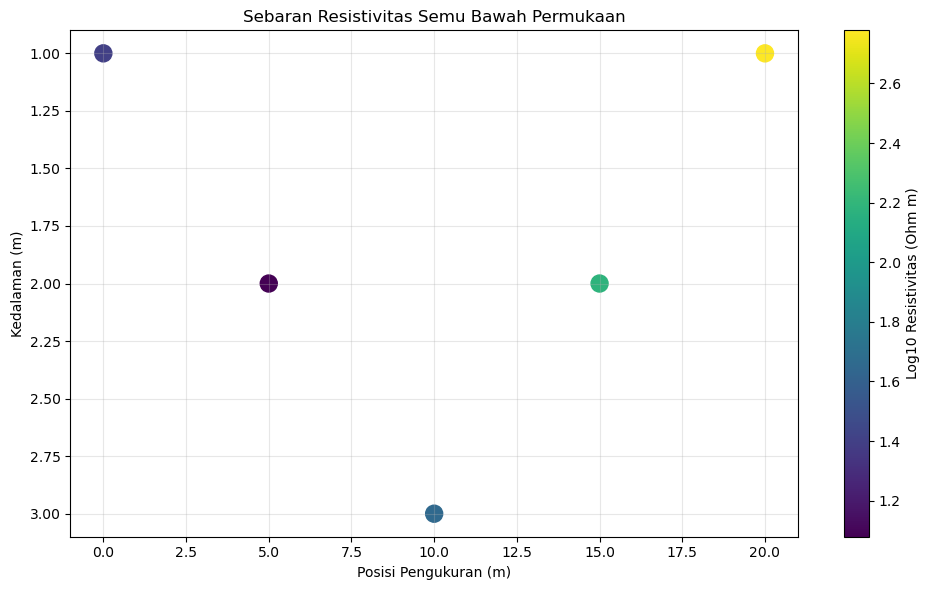

In [8]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# 1. Memasukkan data pengukuran
data = pd.DataFrame({
    "Posisi (m)": [0, 5, 10, 15, 20],
    "Kedalaman (m)": [1, 2, 3, 2, 1],
    "Resistivitas (Ohm m)": [25, 12, 45, 150, 600]
})

# 2. Interpretasi berdasarkan resistivitas
def interpretasi(rho):
    if rho < 10:
        return ("Kemungkinan lempung jenuh air",
                "Resistivitas rendah dapat berkaitan dengan lempung atau fluida konduktif.")
    elif rho < 30:
        return ("Kemungkinan lempung, lanau, atau tanah lembap",
                "Material konduktif dan kadar air dapat menurunkan resistivitas.")
    elif rho < 100:
        return ("Kemungkinan tanah pelapukan atau material campuran",
                "Rentang ini dapat dijumpai pada beragam material dengan kadar air berbeda.")
    elif rho < 500:
        return ("Kemungkinan pasir/kerikil atau batuan lapuk",
                "Resistivitas relatif tinggi dapat menunjukkan material kurang jenuh air.")
    else:
        return ("Kemungkinan batuan kompak atau material kering",
                "Nilai tinggi dapat berkaitan dengan material kering atau kurang konduktif.")

hasil = data["Resistivitas (Ohm m)"].apply(interpretasi)

data["Kemungkinan Material"] = hasil.apply(lambda x: x[0])
data["Alasan Interpretasi"] = hasil.apply(lambda x: x[1])

# 3. Menampilkan tabel hasil
print("TABEL INTERPRETASI RESISTIVITAS")
print(data.to_string(index=False))

# 4. Menyimpan tabel ke Excel
data.to_excel("hasil_interpretasi.xlsx", index=False)
print("\nTabel tersimpan: hasil_interpretasi.xlsx")

# 5. Membuat grafik sebaran data
plt.figure(figsize=(10, 6))

grafik = plt.scatter(
    data["Posisi (m)"],
    data["Kedalaman (m)"],
    c=np.log10(data["Resistivitas (Ohm m)"]),
    cmap="viridis",
    s=150
)

plt.gca().invert_yaxis()
plt.colorbar(grafik, label="Log10 Resistivitas (Ohm m)")
plt.xlabel("Posisi Pengukuran (m)")
plt.ylabel("Kedalaman (m)")
plt.title("Sebaran Resistivitas Semu Bawah Permukaan")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig("grafik_resistivitas.png", dpi=300)
plt.show()

---

# Prompt 2 — Analisis Parameter Seismogram Gempa Lokal

### R — Role

Kamu berperan sebagai **ahli seismologi yang berpengalaman dalam analisis data seismogram**.

### T — Task

Analisis seismogram untuk menentukan waktu tiba gelombang P dan menghitung amplitudo maksimum, periode, serta frekuensi gelombang.

### C — Context

Data seismogram digunakan untuk mengetahui karakteristik gelombang gempa lokal.

### I — Input

Saya akan memberikan gambar seismogram yang memiliki skala waktu dan amplitudo.

### K — Constraints

- Gunakan hanya data yang tersedia pada gambar.
- Jangan membuat nilai yang tidak terdapat pada data.
- Jelaskan proses perhitungan secara bertahap dan gunakan satuan yang benar.

### O — Output

Berikan hasil berupa waktu tiba gelombang P, amplitudo maksimum, periode, frekuensi, dan langkah perhitungannya.

### Q — Quality Criteria

Pastikan hubungan periode dan frekuensi diverifikasi menggunakan rumus matematis.

### V — Verification

Verifikasi menggunakan f = 1/T dan periksa kembali kebenaran satuan serta hasil akhirnya.



=== HASIL ANALISIS SEISMOGRAM ===
1. Waktu Tiba Gelombang P : 2.032 detik
2. Amplitudo Maksimum     : 0.919 satuan
3. Langkah Perhitungan Periode:
   - Waktu puncak gelombang terbaca di: [2.032 2.072 2.112 2.132 2.152 2.182 2.573 2.613 2.633 2.653] detik
   - Selisih waktu antar puncak rata-rata (T) = 0.069 detik
4. Frekuensi (f)          : 1 / T = 1 / 0.069 = 14.502 Hz


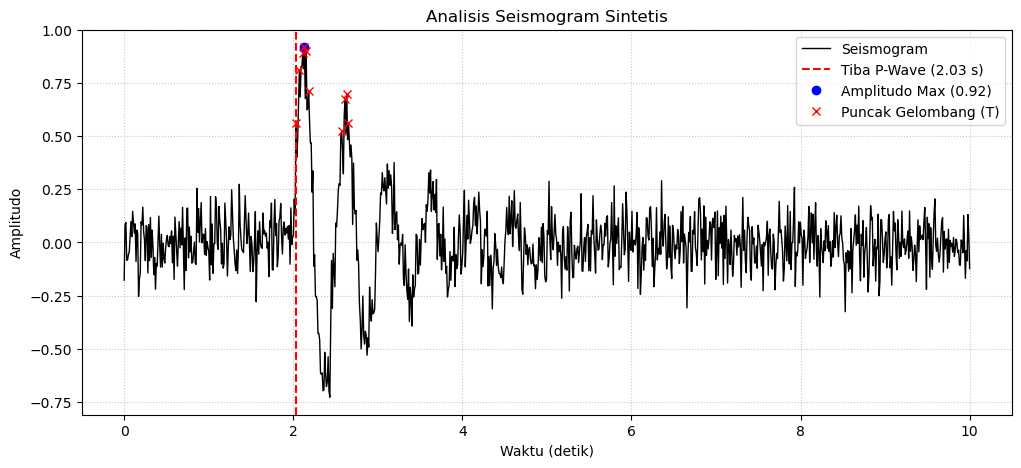

In [2]:

import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import find_peaks


# 1. DATA SEISMOGRAM 

# Membuat data sintetis sebagai contoh (waktu dalam detik, amplitudo dalam mm/s atau counts)
waktu = np.linspace(0, 10, 1000)
# Simulasi gelombang seismik (noise + gelombang utama mulai di detik ke-2)
amplitudo = np.random.normal(0, 0.1, 1000) 
amplitudo[200:600] += np.sin(2 * np.pi * 2 * waktu[200:600]) * np.exp(-(waktu[200:600]-2))

# ==========================================
# 2. ANALISIS PARAMETER SEISMOGRAM
# ==========================================
# A. Menentukan Waktu Tiba Gelombang P (Threshold sederhana)
# Misalnya, gelombang P diasumsikan tiba saat amplitudo melewati batas 0.3
threshold_p = 0.3
waktu_tiba_p_index = np.where(np.abs(amplitudo) > threshold_p)[0][0]
waktu_tiba_p = waktu[waktu_tiba_p_index]

# B. Menentukan Amplitudo Maksimum
amp_max_index = np.argmax(np.abs(amplitudo))
amplitudo_maksimum = np.abs(amplitudo[amp_max_index])
waktu_amp_max = waktu[amp_max_index]

# C. Menghitung Periode (T)
# Mencari puncak-puncak gelombang (peaks) pada fase utama
puncak_index, _ = find_peaks(amplitudo, height=0.5)
waktu_puncak = waktu[puncak_index]

# Periode adalah selisih waktu antara dua puncak yang berurutan
# Kita ambil rata-rata selisih waktu antar puncak
selisih_waktu = np.diff(waktu_puncak)
periode = np.mean(selisih_waktu)

# D. Menghitung Frekuensi (f) dan Verifikasi
frekuensi = 1 / periode

# ==========================================
# 3. MENAMPILKAN HASIL PERHITUNGAN
# ==========================================
print("=== HASIL ANALISIS SEISMOGRAM ===")
print(f"1. Waktu Tiba Gelombang P : {waktu_tiba_p:.3f} detik")
print(f"2. Amplitudo Maksimum     : {amplitudo_maksimum:.3f} satuan")
print(f"3. Langkah Perhitungan Periode:")
print(f"   - Waktu puncak gelombang terbaca di: {np.round(waktu_puncak, 3)} detik")
print(f"   - Selisih waktu antar puncak rata-rata (T) = {periode:.3f} detik")
print(f"4. Frekuensi (f)          : 1 / T = 1 / {periode:.3f} = {frekuensi:.3f} Hz")
print("=================================")

# ==========================================
# 4. VISUALISASI SEISMOGRAM
# ==========================================
plt.figure(figsize=(12, 5))
plt.plot(waktu, amplitudo, label='Seismogram', color='black', linewidth=1)

# Menandai Waktu Tiba Gelombang P
plt.axvline(x=waktu_tiba_p, color='red', linestyle='--', label=f'Tiba P-Wave ({waktu_tiba_p:.2f} s)')

# Menandai Amplitudo Maksimum
plt.plot(waktu_amp_max, amplitudo[amp_max_index], 'bo', label=f'Amplitudo Max ({amplitudo_maksimum:.2f})')

# Menandai Puncak Gelombang untuk perhitungan Periode
plt.plot(waktu_puncak, amplitudo[puncak_index], 'rx', label='Puncak Gelombang (T)')

plt.title('Analisis Seismogram Sintetis')
plt.xlabel('Waktu (detik)')
plt.ylabel('Amplitudo')
plt.legend()
plt.grid(True, linestyle=':', alpha=0.7)
plt.show()


---

# Prompt 3 — Analisis Spasial Kemiringan Lereng

### R — Role

Kamu berperan sebagai **ahli geofisika dan GIS yang memahami analisis spasial kebencanaan**.

### T — Task

Analisis kemiringan lereng suatu wilayah untuk mengidentifikasi area yang memiliki kondisi lereng lebih terjal dan dapat menjadi salah satu parameter dalam analisis kerawanan longsor.

### C — Context

Analisis ini dibutuhkan untuk identifikasi awal kerawanan longsor.

### I — Input

Saya akan memberikan data DEM dan hasil kemiringan lereng dalam satuan derajat atau persen.

### K — Constraints

- Fokus hanya pada parameter kemiringan lereng.
- Jangan menyatakan suatu wilayah pasti mengalami longsor hanya berdasarkan kemiringan.
- Bedakan antara kondisi lereng, potensi kerawanan, dan risiko bencana.
- Gunakan bahasa mahasiswa yang sederhana.

### O — Output

Jelaskan distribusi kemiringan lereng, kelas lereng yang ditemukan, area yang perlu mendapat perhatian, serta keterbatasan analisis.

### Q — Quality Criteria

Klasifikasi lereng harus akurat dan narasinya mudah dipahami.

### V — Verification

Periksa kembali klasifikasi dan pastikan satuan derajat atau persen tidak tertukar.



=== DISTRIBUSI KELAS KEMIRINGAN LERENG ===
Datar (0-8°): 1.07%
Landai (8-15°): 17.57%
Agak Curam (15-25°): 33.22%
Curam (25-45°): 34.99%
Sangat Curam (>45°): 13.15%


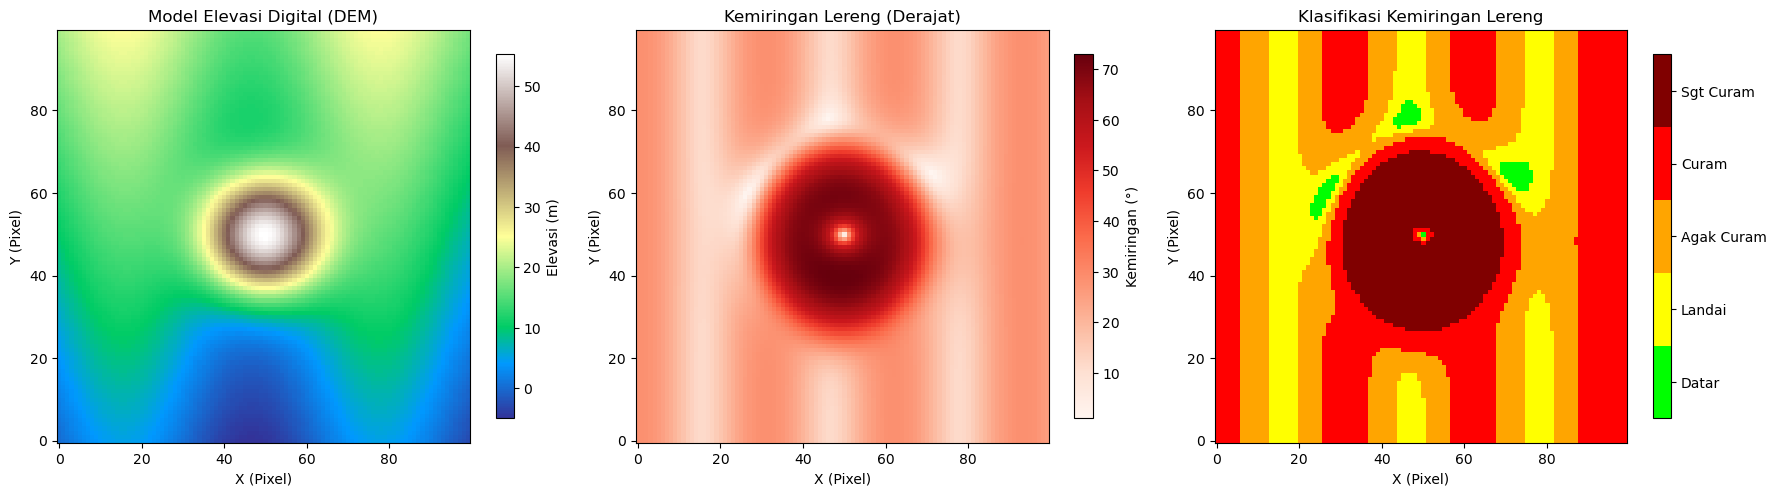

In [3]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

# ==========================================
# 1. SIMULASI DATA DEM 
# ==========================================
# Membuat grid koordinat
x = np.linspace(0, 100, 100)
y = np.linspace(0, 100, 100)
X, Y = np.meshgrid(x, y)

# Membuat topografi buatan (gabungan bukit dan area landai)
DEM = 50 * np.exp(-((X-50)**2 + (Y-50)**2)/200) + 5 * np.sin(X/10) + 0.2 * Y

# ==========================================
# 2. MENGHITUNG KEMIRINGAN LERENG (Derajat)
# ==========================================
# Asumsi resolusi spasial (cell size) = 1 meter
resolusi = 1.0 
dy, dx = np.gradient(DEM, resolusi, resolusi)

# Menghitung slope dalam radian, lalu konversi ke DERAJAT
slope_rad = np.arctan(np.sqrt(dx**2 + dy**2))
slope_deg = np.degrees(slope_rad)

# ==========================================
# 3. KLASIFIKASI KEMIRINGAN LERENG
# ==========================================
# Kita pakai klasifikasi umum (satuan derajat):
# 1: 0 - 8   (Datar)
# 2: 8 - 15  (Landai)
# 3: 15 - 25 (Agak Curam)
# 4: 25 - 45 (Curam)
# 5: > 45    (Sangat Curam)

slope_class = np.zeros_like(slope_deg)
slope_class[(slope_deg >= 0) & (slope_deg < 8)] = 1
slope_class[(slope_deg >= 8) & (slope_deg < 15)] = 2
slope_class[(slope_deg >= 15) & (slope_deg < 25)] = 3
slope_class[(slope_deg >= 25) & (slope_deg < 45)] = 4
slope_class[(slope_deg >= 45)] = 5

# Menghitung persentase luasan tiap kelas
total_pixel = slope_class.size
persentase = {
    "Datar (0-8°)": np.sum(slope_class == 1) / total_pixel * 100,
    "Landai (8-15°)": np.sum(slope_class == 2) / total_pixel * 100,
    "Agak Curam (15-25°)": np.sum(slope_class == 3) / total_pixel * 100,
    "Curam (25-45°)": np.sum(slope_class == 4) / total_pixel * 100,
    "Sangat Curam (>45°)": np.sum(slope_class == 5) / total_pixel * 100
}

print("=== DISTRIBUSI KELAS KEMIRINGAN LERENG ===")
for kelas, persen in persentase.items():
    print(f"{kelas}: {persen:.2f}%")

# ==========================================
# 4. VISUALISASI HASIL
# ==========================================
fig, ax = plt.subplots(1, 3, figsize=(18, 5))

# Plot 1: DEM
im1 = ax[0].imshow(DEM, cmap='terrain', origin='lower')
ax[0].set_title('Model Elevasi Digital (DEM)')
fig.colorbar(im1, ax=ax[0], label='Elevasi (m)', shrink=0.8)

# Plot 2: Slope (Derajat)
im2 = ax[1].imshow(slope_deg, cmap='Reds', origin='lower')
ax[1].set_title('Kemiringan Lereng (Derajat)')
fig.colorbar(im2, ax=ax[1], label='Kemiringan (°)', shrink=0.8)

# Plot 3: Klasifikasi Slope
cmap_class = ListedColormap(['#00FF00', '#FFFF00', '#FFA500', '#FF0000', '#800000'])
im3 = ax[2].imshow(slope_class, cmap=cmap_class, origin='lower', vmin=0.5, vmax=5.5)
ax[2].set_title('Klasifikasi Kemiringan Lereng')
cbar = fig.colorbar(im3, ax=ax[2], ticks=[1, 2, 3, 4, 5], shrink=0.8)
cbar.ax.set_yticklabels(['Datar', 'Landai', 'Agak Curam', 'Curam', 'Sgt Curam'])

for a in ax:
    a.set_xlabel('X (Pixel)')
    a.set_ylabel('Y (Pixel)')

plt.tight_layout()
plt.show()


---

# Prompt 4 — Interpretasi Data Anomali Gravitasi

### R — Role

Kamu berperan sebagai **ahli geofisika yang berpengalaman dalam metode gravitasi**.

### T — Task

Analisis data anomali gravitasi untuk mengidentifikasi kemungkinan variasi densitas material bawah permukaan.

### C — Context

Metode gravitasi memanfaatkan perbedaan medan gravitasi yang berkaitan dengan variasi densitas batuan.

### I — Input

Saya akan memberikan data koordinat, elevasi, dan nilai anomali gravitasi.

### K — Constraints

- Jangan menganggap anomali positif atau negatif langsung menunjukkan jenis batuan tertentu.
- Jelaskan interpretasi berdasarkan konsep densitas dan gunakan istilah "indikasi" atau "kemungkinan" jika hasilnya tidak pasti.

### O — Output

Identifikasi zona anomali tinggi dan rendah, kemudian jelaskan kemungkinan hubungan zona tersebut dengan variasi densitas bawah permukaan.

### Q — Quality Criteria

Penjelasan harus objektif tanpa menebak litologi secara absolut.

### V — Verification

Pastikan interpretasi sesuai dengan prinsip metode gravitasi dan bedakan secara jelas antara fakta data pengukuran dengan interpretasi geologi.

Contoh 5 Data Pertama:
        X (m)       Y (m)  Elevasi (m)  Anomali (mGal)
0  374.540119   31.429186    35.681266       -4.935396
1  950.714306  636.410411    13.365599       -5.267124
2  731.993942  314.355981    16.465149       -2.277776
3  598.658484  508.570691    45.942168        7.055487
4  156.018640  907.566474    34.257162       -6.000328
--------------------------------------------------


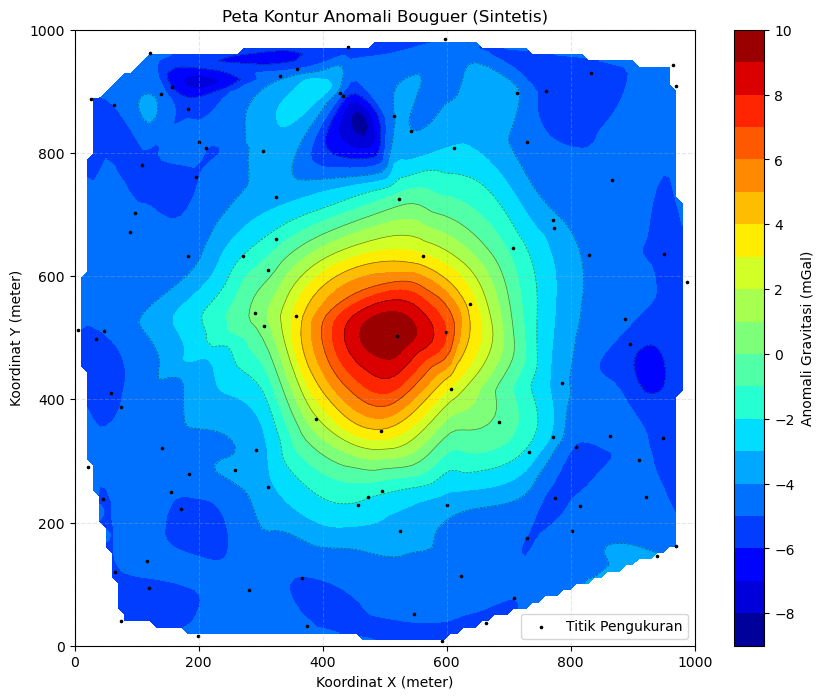

In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.interpolate import griddata

# ==========================================
# 1. DATA GRAVITASI 
# ==========================================
# Membuat 100 titik data sintetis acak untuk contoh
np.random.seed(42)
x = np.random.uniform(0, 1000, 100) # Koordinat X (meter)
y = np.random.uniform(0, 1000, 100) # Koordinat Y (meter)
elevasi = np.random.uniform(10, 50, 100) # Elevasi (meter) - sebagai informasi data

# Membuat anomali buatan (satu zona tinggi di tengah, sekitarnya rendah)
# Satuan anomali biasanya miligal (mGal)
anomali = 15 * np.exp(-((x-500)**2 + (y-500)**2)/40000) - 5 + np.random.normal(0, 0.5, 100)

# Simpan ke dalam tabel (DataFrame) agar rapi
df = pd.DataFrame({'X (m)': x, 'Y (m)': y, 'Elevasi (m)': elevasi, 'Anomali (mGal)': anomali})
print("Contoh 5 Data Pertama:")
print(df.head())
print("-" * 50)

# ==========================================
# 2. GRIDDING DATA (Membuat Peta Kontur)
# ==========================================
# Membuat grid / jaring-jaring teratur untuk interpolasi
grid_x, grid_y = np.mgrid[0:1000:100j, 0:1000:100j]

# Interpolasi data titik (scatter) menjadi grid permukaan (surface) menggunakan metode cubic
grid_anomali = griddata((x, y), anomali, (grid_x, grid_y), method='cubic')

# ==========================================
# 3. VISUALISASI PETA ANOMALI GRAVITASI
# ==========================================
plt.figure(figsize=(10, 8))

# Membuat peta kontur berwarna
kontur = plt.contourf(grid_x, grid_y, grid_anomali, levels=20, cmap='jet')
# Menambahkan garis kontur
plt.contour(grid_x, grid_y, grid_anomali, levels=10, colors='black', linewidths=0.5, alpha=0.5)

# Menandai titik pengukuran asli
plt.scatter(x, y, c='black', s=10, label='Titik Pengukuran', marker='.')

plt.colorbar(kontur, label='Anomali Gravitasi (mGal)')
plt.title('Peta Kontur Anomali Bouguer (Sintetis)')
plt.xlabel('Koordinat X (meter)')
plt.ylabel('Koordinat Y (meter)')
plt.legend(loc='lower right')
plt.grid(linestyle='--', alpha=0.3)

plt.show()

---

# Prompt 5 — Eksplorasi Sistem Panas Bumi

### R — Role

Kamu berperan sebagai **ahli geofisika yang fokus pada eksplorasi sistem panas bumi**.

### T — Task

Analisis data temperatur dan kondisi geologi untuk mengidentifikasi indikasi awal adanya sistem panas bumi.

### C — Context

Identifikasi ini bertujuan untuk memetakan potensi panas bumi tahap awal.

### I — Input

Data yang saya berikan berupa temperatur, kedalaman, koordinat titik pengukuran, dan informasi litologi.

### K — Constraints

- Jangan menyatakan keberadaan reservoir panas bumi secara pasti hanya berdasarkan temperatur.
- Bedakan antara hasil pengamatan dan interpretasi serta jelaskan keterbatasan data.

### O — Output

Buat tabel data, kemudian jelaskan perubahan temperatur terhadap kedalaman, zona dengan temperatur relatif tinggi, kemungkinan hubungan dengan kondisi geologi, dan keterbatasan interpretasinya.

### Q — Quality Criteria

Tabel disajikan dengan rapi dan argumen didukung oleh perubahan gradien geotermal.

### V — Verification

Pastikan satuan temperatur dan kedalaman benar serta periksa kembali hubungan matematis/gradien antara temperatur dan kedalaman sebelum memberikan hasil akhir.

=== TABEL DATA TEMPERATUR DAN LITOLOGI ===
Titik  X_UTM   Y_UTM  Kedalaman (m)  Temperatur (°C)                Litologi  Gradien (°C/100m)
 S-01 780100 9450100             10             26.5                     Tuf               15.0
 S-01 780100 9450100             50             29.0                     Tuf                8.0
 S-01 780100 9450100            100             32.5                 Andesit                7.5
 S-02 781500 9451200             10             28.0                  Breksi               30.0
 S-02 781500 9451200             50             45.0           Breksi ubahan               40.0
 S-02 781500 9451200            100             75.0 Andesit tersilisifikasi               50.0
 S-03 782200 9450800             10             27.0                     Tuf               20.0
 S-03 782200 9450800             50             31.0                     Tuf               12.0
 S-03 782200 9450800            100             38.0                 Andesit               13

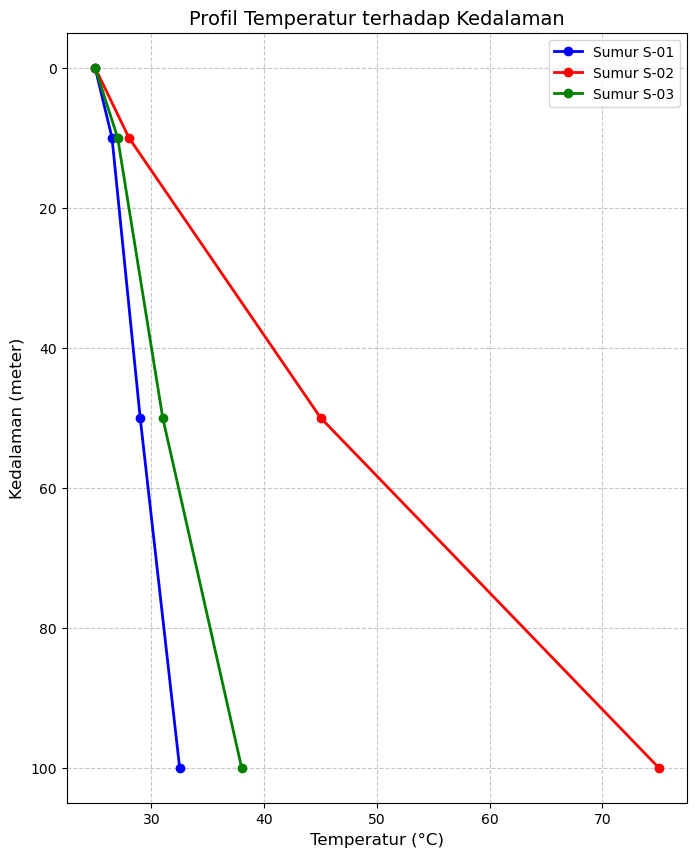

In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# ==========================================
# 1. INPUT DATA 
# ==========================================
data_lapangan = {
    'Titik': ['S-01', 'S-01', 'S-01', 'S-02', 'S-02', 'S-02', 'S-03', 'S-03', 'S-03'],
    'X_UTM': [780100, 780100, 780100, 781500, 781500, 781500, 782200, 782200, 782200],
    'Y_UTM': [9450100, 9450100, 9450100, 9451200, 9451200, 9451200, 9450800, 9450800, 9450800],
    'Kedalaman (m)': [10, 50, 100, 10, 50, 100, 10, 50, 100],
    'Temperatur (°C)': [26.5, 29.0, 32.5, 28.0, 45.0, 75.0, 27.0, 31.0, 38.0],
    'Litologi': ['Tuf', 'Tuf', 'Andesit', 'Breksi', 'Breksi ubahan', 'Andesit tersilisifikasi', 'Tuf', 'Tuf', 'Andesit']
}

df = pd.DataFrame(data_lapangan)

# ==========================================
# 2. MENGHITUNG GRADIEN GEOTERMAL
# ==========================================
# Menghitung gradien temperatur (°C/100m) untuk setiap sumur
# Asumsi temperatur permukaan rata-rata = 25 °C pada kedalaman 0 m
temp_permukaan = 25.0
df['Gradien (°C/100m)'] = ((df['Temperatur (°C)'] - temp_permukaan) / df['Kedalaman (m)']) * 100

print("=== TABEL DATA TEMPERATUR DAN LITOLOGI ===")
display(df) if 'IPython' in globals() else print(df.to_string(index=False))
print("-" * 50)

# ==========================================
# 3. VISUALISASI TEMPERATUR VS KEDALAMAN
# ==========================================
plt.figure(figsize=(8, 10))

sumur_unik = df['Titik'].unique()
colors = ['blue', 'red', 'green']

for i, sumur in enumerate(sumur_unik):
    subset = df[df['Titik'] == sumur]
    # Tambahkan titik permukaan (0m, 25°C) untuk awal grafik
    kedalaman_plot = np.insert(subset['Kedalaman (m)'].values, 0, 0)
    temp_plot = np.insert(subset['Temperatur (°C)'].values, 0, temp_permukaan)
    
    plt.plot(temp_plot, kedalaman_plot, marker='o', label=f'Sumur {sumur}', color=colors[i], linewidth=2)

# Normalnya, profil kedalaman pada sumur diplot dengan sumur Y terbalik (0 di atas)
plt.gca().invert_yaxis()

plt.title('Profil Temperatur terhadap Kedalaman', fontsize=14)
plt.xlabel('Temperatur (°C)', fontsize=12)
plt.ylabel('Kedalaman (meter)', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.7)
plt.legend()
plt.show()